# InSAR4SM case study: Ford Dry Lake, California (Nov 2025 – Nov 2026)

**What this notebook shows:** one year of InSAR4SM surface soil moisture at the Ford Dry Lake SCAN station (Mojave Desert, California), from **NISAR (L-band)** and **Sentinel-1 (C-band)**, compared with **in-situ measurements** (ISMN, 5 cm) and with the **ERA5-Land** reanalysis that most users would otherwise use.

**Key results** (5 satellite tracks, 172 estimates, pooled; ubRMSE is the error after removing the mean bias):

| | RMSE | bias | ubRMSE | R |
|---|---|---|---|---|
| **InSAR4SM** (2 × 2 km mean) | **1.7 %** | −0.9 % | **1.4 %** | **0.90** |
| ERA5-Land (9 km) | 4.0 % | −3.4 % | 2.1 % | 0.84 |

- InSAR4SM has a lower RMSE than ERA5-Land on each of the 5 tracks. **Much of the RMSE gap is ERA5-Land's dry bias**: without bias the errors are 1.4 % and 2.1 %.
- **On wetter dates** (in situ ≥ 6 %, 48 estimates) ERA5-Land follows the variations better (R 0.89 vs 0.73), although its RMSE is higher (5.5 % vs 2.8 %).
- **Dry-season values are partly prescribed:** the inversion fixes the driest date at 2.8 % and caps the other dry dates at 3.8 %.
- The tracks together give an estimate on **137 days**: a median of 2 days apart, at most 11.

**Before you run it:** the in-situ data are not in this repository, because the [ISMN terms](https://ismn.earth/en/terms-and-conditions/) do not allow redistribution. Download station *FordDryLake* (network SCAN, 5 cm) with your own ISMN account, then set `ISMN_FILE` below. No SAR download is needed.

In [1]:
import pandas as pd
import os
import case_study as cs

# your own ISMN download: .stm file, or CSV with columns date_time, soil_moisture
ISMN_FILE = os.environ.get('ISMN_FILE', 'path/to/FordDryLake_5cm.stm')

pd.set_option('display.precision', 2)
data = cs.load_results(ISMN_FILE)
h = cs.headline(data)
print('InSAR4SM: RMSE {rmse_insar:.2f} %, R {r_insar:.2f} | ERA5-Land: RMSE {rmse_era5:.2f} %, R {r_era5:.2f}'.format(**h))
print('{n_obs} estimates from {n_tracks} tracks on {n_dates} distinct days; median gap {median_gap_days:.0f} days, max gap {max_gap_days} days'.format(**h))

InSAR4SM: RMSE 1.68 %, R 0.90 | ERA5-Land: RMSE 3.95 %, R 0.84
172 estimates from 5 tracks on 137 distinct days; median gap 2 days, max gap 11 days


## 1. Site and data

| | |
|---|---|
| **Site** | Ford Dry Lake SCAN station (ISMN), 33.6547 N, −115.0976 E, Mojave Desert, California |
| **Climate / cover** | Hot desert (Köppen BWh), sparse shrubland, flat (slope 0.2°) |
| **Soil** | Sand 79 %, clay 11 % (ISMN station metadata) |
| **Area of interest** | 2 × 2 km square centred on the station (`tests/data/FordDryLake_aoi.geojson`) |
| **Period** | 2025-11-22 → 2026-11-11 (NISAR estimates end on 2026-10-18) |
| **SAR** | NISAR L2 GSLC (L-band, HH) and Sentinel-1 OPERA CSLC-S1 (C-band, VV). Only the AOI window of each product is read; nothing is downloaded in full |
| **Meteorology** | ERA5-Land hourly (precipitation, skin temperature, layer-1 soil moisture) |
| **Reference** | ISMN in-situ soil moisture, 5 cm, hourly (Stevens HydraProbe) |

InSAR4SM processes every satellite track separately. The tracks over the AOI:

In [2]:
data['tracks'][['sensor', 'track', 'n_acquisitions', 'first', 'last', 'revisit_days',
                'median_consecutive_coherence', 'median_incLocal', 'valid_fraction', 'used']]

,sensor,track,n_acquisitions,first,last,revisit_days,median_consecutive_coherence,median_incLocal,valid_fraction,used
0,NISAR,005A,26,20251122,20261012,12.0,0.30,44.16,1.00,True
1,NISAR,085D,25,20251128,20261018,12.0,0.27,45.13,1.00,True
2,NISAR,106A,23,20251223,20261019,12.0,0.39,33.60,0.02,False
3,S1,100D,29,20251201,20261109,12.0,0.49,45.76,0.76,True
4,S1,166A,31,20251130,20261108,12.0,0.67,40.38,1.00,True
5,S1,173D,61,20251124,20261108,6.0,0.65,34.91,1.00,True


- `valid_fraction`: share of the processed grid (AOI plus a 250 m margin) with SAR data on every date.
- **NISAR track 106A** is not used: its frame only touches the edge of the AOI (2 % coverage), so it has no estimate.
- **NISAR 157D** (9 acquisitions) was below the minimum of 10 acquisitions per track and was not processed.
- Sentinel-1 track 100D covers 76 % of that grid (the AOI is at the edge of the burst).
- Sentinel-1 173D has a 6-day revisit (Sentinel-1A + 1C); the other tracks have 12 days.

## 2. One year of soil moisture

All InSAR4SM estimates (2 × 2 km mean, each point is one acquisition of one track) against the in-situ sensor and ERA5-Land. The top panel shows ERA5-Land daily precipitation.

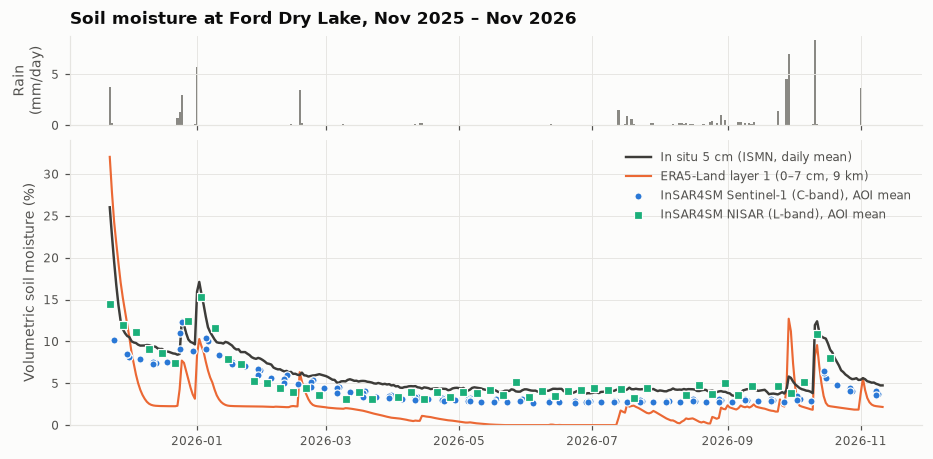

In [3]:
fig = cs.fig_overview_timeseries(data)

- **Rain events:** InSAR4SM responds to the winter rain and to the October 2026 storm, but it underestimates the highest peaks (e.g. 10 % against 19 % in situ on 2025-11-24).
- **Dry season:** it stays near 3–5 %. This is partly by construction, since the inversion prescribes the dry state (2.8 %): 64 % of the Sentinel-1 means and 29 % of the NISAR means lie between 2.5 and 3.8 %.
- **ERA5-Land:** it is too dry most of the time, with values near 0 % from mid-May to mid-July, and it reacts too strongly to some rain events and too weakly to others.
- **Bias:** InSAR4SM is slightly too low overall (−0.9 %).

## 3. Accuracy per track

One panel per track: the in-situ daily mean (line), InSAR4SM (connected markers) and ERA5-Land at the same acquisition times (diamonds).

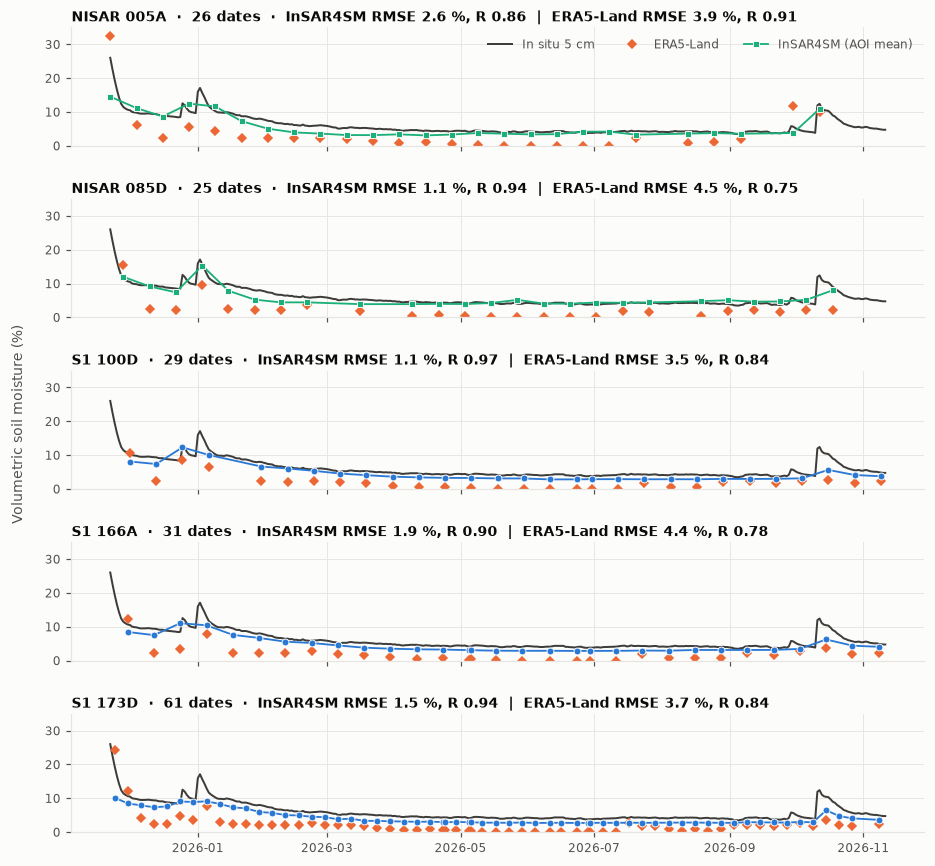

In [4]:
fig = cs.fig_tracks_timeseries(data)

In [5]:
m = cs.metrics_table(data)
m.pivot_table(index='tracks', columns='product', values=['RMSE', 'bias', 'R'], sort=False).round(2)

RMSE                                    \
product        InSAR4SM (AOI mean) InSAR4SM (station cell) ERA5-Land   
tracks                                                                 
NISAR 005A                    2.56                    3.03      3.90   
NISAR 085D                    1.14                    3.51      4.53   
S1 100D                       1.06                    1.36      3.52   
S1 166A                       1.87                    2.78      4.42   
S1 173D                       1.54                    1.92      3.65   
All Sentinel-1                1.54                    2.07      3.83   
All NISAR                     1.99                    3.27      4.22   
All tracks                    1.68                    2.49      3.95   

                              bias                                    \
product        InSAR4SM (AOI mean) InSAR4SM (station cell) ERA5-Land   
tracks                                                                 
NISAR 005A                   -0.62                   -1.71     -2.63   
NISAR 085D                   -0.46                   -1.97     -3.94   
S1 100D                      -0.76                   -0.93     -3.18   
S1 166A                      -1.54                   -2.34     -4.10   
S1 173D                      -1.04                   -0.99     -3.13   
All Sentinel-1               -1.10                   -1.32     -3.39   
All NISAR                    -0.54                   -1.84     -3.27   
All tracks                   -0.93                   -1.47     -3.36   

                                 R                                    
product        InSAR4SM (AOI mean) InSAR4SM (station cell) ERA5-Land  
tracks                                                                
NISAR 005A                    0.86                    0.87      0.91  
NISAR 085D                    0.94                    0.34      0.75  
S1 100D                       0.97                    0.93      0.84  
S1 166A                       0.90                    0.92      0.78  
S1 173D                       0.94                    0.82      0.84  
All Sentinel-1                0.93                    0.83      0.81  
All NISAR                     0.88                    0.74      0.86  
All tracks                    0.90                    0.79      0.84

- **RMSE:** lower than ERA5-Land on every track (1.1–2.6 % vs 3.5–4.5 %).
- **Correlation:** higher on 4 of the 5 tracks. ERA5-Land is better on NISAR 005A (R 0.91 vs 0.86).
- **Station cell:** the single cell that contains the station is noisier than the 2 × 2 km mean (pooled RMSE 2.5 %; R only 0.34 on NISAR 085D).
- **Sensors:** Sentinel-1 reaches RMSE 1.5 %, R 0.93 and NISAR 2.0 %, R 0.88, with the same default settings.
- The 172 estimates are not independent: several tracks observe the same wet and dry periods.

### Dry and wet dates

Most dates are dry, so the pooled scores mainly describe dry soil. Split at 6 % in situ (a threshold chosen after the run):

In [6]:
cs.wetness_table(data)

,dates,product,N,bias,RMSE,ubRMSE,R
0,in situ < 6 %,InSAR4SM (AOI mean),124,-0.68,0.92,0.62,0.59
1,in situ < 6 %,ERA5-Land,124,-2.95,3.19,1.21,0.42
2,in situ >= 6 %,InSAR4SM (AOI mean),48,-1.60,2.83,2.33,0.73
3,in situ >= 6 %,ERA5-Land,48,-4.41,5.45,3.21,0.89
4,all dates,InSAR4SM (AOI mean),172,-0.93,1.68,1.40,0.90
5,all dates,ERA5-Land,172,-3.36,3.95,2.09,0.84


In [7]:
cs.dry_state_share(data).rename('share of AOI means within 2.5-3.8 %').to_frame()

,share of AOI means within 2.5-3.8 %
sensor,
NISAR,0.29
S1,0.64


On wet dates InSAR4SM has the lower error, but ERA5-Land correlates better. ERA5-Land precipitation and temperature are also **inputs** of InSAR4SM (selection of the dry dates), so the two are not fully independent.

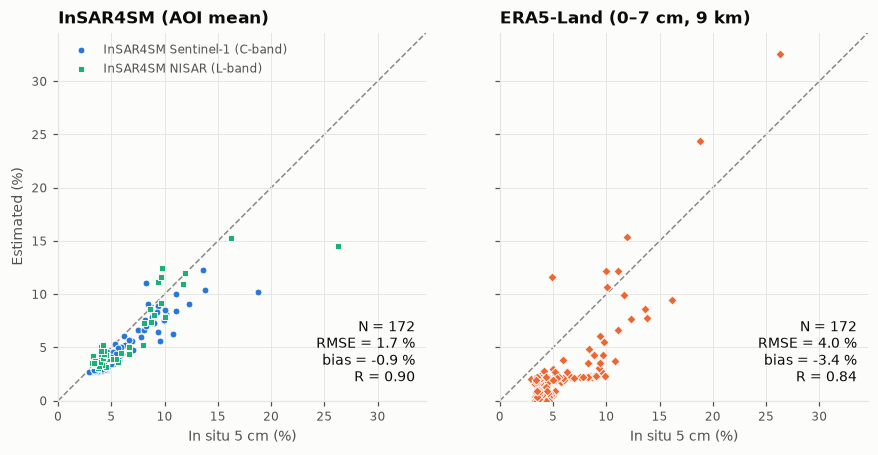

In [8]:
fig = cs.fig_scatter(data)

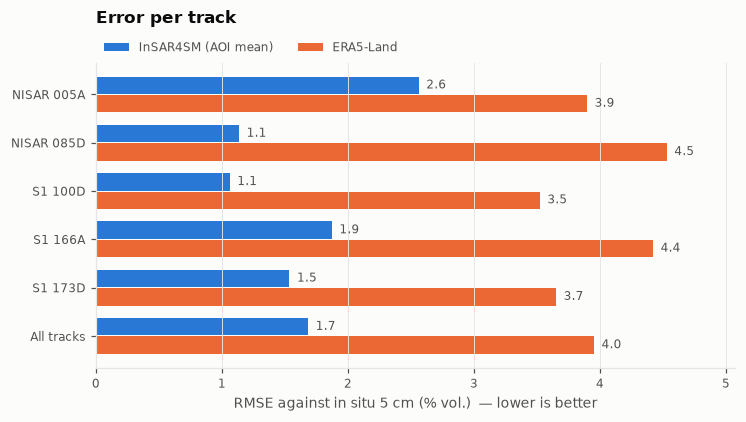

In [9]:
fig = cs.fig_rmse_bars(data)

## 4. Soil moisture maps

InSAR4SM gives an estimate every 125 m, each from a 250 × 250 m window, so neighbouring values overlap. Here are the driest and the wettest date of the track with most acquisitions (Sentinel-1 173D, 61). The 2 × 2 km AOI spans two ERA5-Land cells, whose average is used in this study.

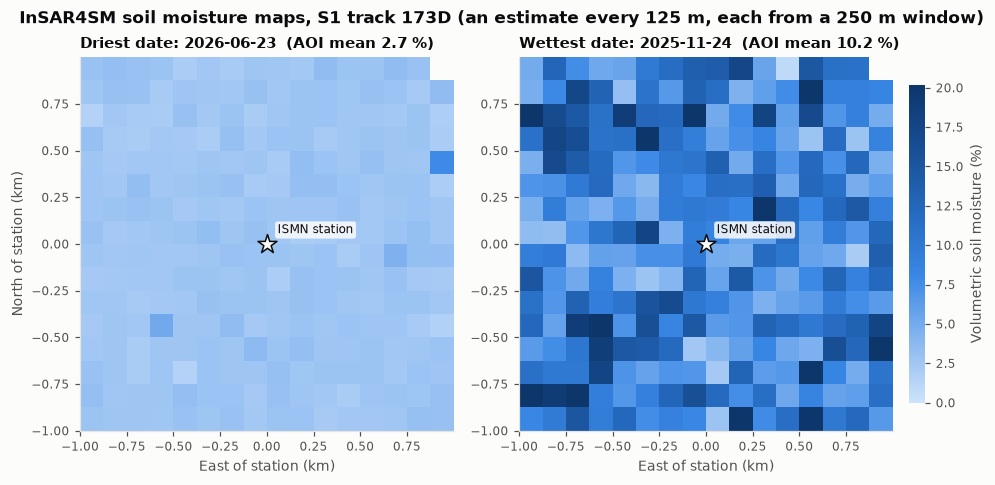

In [10]:
fig = cs.fig_maps(data)

- On the **driest date** the AOI is nearly uniform, at about 3 %.
- **After the November 2025 rain** the values differ strongly between neighbouring cells. **This study cannot tell how much of that is real**: there is only one station, so the spatial pattern is not validated.
- Prefer spatially averaged values.

## 5. What this means for users

**What this case study supports:**
- **Level of soil moisture:** at this desert site, lower error than ERA5-Land, with no tuning to the in-situ soil moisture.
- **Revisit:** an estimate every ~2 days (median) by combining NISAR and Sentinel-1 tracks.
- **Effort:** only the AOI window of each product is read. The run took about 2.5 hours, of which about 2.3 were data access.

**Limitations:**
- One site and one year, in a hot desert with sparse vegetation, where the method is expected to work best. Other conditions need their own validation.
- Dry values are largely set by the prescribed dry state (2.8 %), which happens to suit this site. Elsewhere it may not.
- The inputs also include ERA5-Land precipitation and temperature, and the station's soil texture. A run elsewhere would use a soil map instead.
- The reference is a single 5 cm sensor compared with a 2 × 2 km mean; the radar senses different depths.
- The parameters were tuned for C-band, and **phase flattening of the NISAR GSLC products has not been confirmed yet** (InSAR4SM assumes zero perpendicular baselines). Treat the NISAR results as preliminary.

## 6. Reproduce

```bash
conda env create -f INSAR4SM_env.yml && conda activate insar4sm
# NASA Earthdata credentials in ~/.netrc, Copernicus CDS key in ~/.cdsapirc
python tests/smoke/run_ford_dry_lake.py --project-dir <RUN_DIR> --ismn-csv <ISMN_5cm.stm> \
    --time-start 20251122T000000 --time-end 20261111T230000 --ds --min-acquisitions 10   # ~2.5 h
python case_studies/FordDryLake/prepare_results.py --run-dir <RUN_DIR>
ISMN_FILE=<ISMN_5cm.stm> jupyter lab case_studies/FordDryLake/FordDryLake_case_study.ipynb
```

The ISMN data (station *FordDryLake*, network SCAN, 5 cm) must be downloaded by each user from https://ismn.earth, after accepting its terms (scientific use only, no redistribution).

## References
- Karamvasis, K., & Karathanassi, V. (2023). Soil moisture estimation from Sentinel-1 interferometric observations over arid regions. *Computers & Geosciences*, 178, 105410. https://doi.org/10.1016/j.cageo.2023.105410
- Katsamas, G., Karamvasis, K., & Karathanassi, V. (2026). Toward Improved Soil Moisture Retrieval Using NISAR InSAR Closure Phase Measurements. *EARSeL Symposium, Athens*. [PDF](https://drive.google.com/file/d/1nKk2JU313nhIxNLPmR2ZAa3G-Cnvtlm3/view?usp=drive_link)

## Acknowledgements
<a href="https://moistx.com/"><img src="../../figures/moistx_logo.png" width="160" alt="moistX"></a>

The development of InSAR4SM is supported by [moistX](https://moistx.com/). The NISAR and Sentinel-1 geocoded-SLC workflow was contributed by Giorgos Katsamas ([@GiorgosKatsamas](https://github.com/GiorgosKatsamas)).

**Data credits:**
- **In situ:** International Soil Moisture Network (Dorigo et al., 2021, *Hydrol. Earth Syst. Sci.* 25, 5749–5804), network SCAN (USDA NRCS).
- **Meteorology:** ERA5-Land (Muñoz-Sabater et al., 2021), Copernicus Climate Change Service.
- **SAR:** NISAR L2 GSLC (NASA/ISRO, ASF DAAC); OPERA L2 CSLC-S1 (NASA JPL, ASF DAAC), containing modified Copernicus Sentinel data 2025–2026.